# Восстановление интенсивностей и сети: синтетический эксперимент v2

Исследуем восстановление известных параметров, влияние размера выборки и правой цензуры.
Это сеть состояний с одним активным состоянием; общий параллельный Petri net здесь не моделируется.
Все времена — в днях. Для генерации используем `Simulator` с независимыми экспоненциальными
часами по рёбрам и переходом по **минимуму времён**, включая петли и возвраты.

Старый генератор `datasets.generate_ad` использует другую модель и в этом опыте не участвует.
Практические настройки: 1200 train, 400 test, 3 повтора для каждого размера, 300 путей прогноза.

## 1. Подготовка и известная истина

Ячейка работает из корня проекта и из `dima`. Нужны NumPy, pandas, SciPy, Matplotlib и IPython;
PM4Py и Graphviz не требуются. Структура задана до генерации. Истинные `rate` — интенсивности
отдельных часов, а не обратные средние наблюдаемых интервалов выбранного ребра.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "dima/survpm/src/survpm").is_dir())
sys.path.insert(0, str(ROOT / "dima/survpm/src"))
from survpm import (EventLog, Network, ProcessModel, ExponentialTransitionModel,
                    ObjectStream, Simulator, Forecaster, discover,
                    DirectlyFollowsBackend, evaluate, compare, compare_networks)
from survpm import datasets
from survpm.log import censoring_summary
from survpm.viz import MatplotlibVisualizer
pd.set_option("display.precision", 4, "display.max_columns", 20)

,src,dst,true_rate,true_winner_p,true_min_mean_days,true_clock_mean_days
0,A,B,0.35,0.7000,2.0000,2.8571
1,A,C,0.15,0.3000,2.0000,6.6667
2,B,A,0.06,0.1429,2.3810,16.6667
3,B,B,0.04,0.0952,2.3810,25.0000
4,B,C,0.20,0.4762,2.3810,5.0000
5,B,D,0.12,0.2857,2.3810,8.3333
6,C,B,0.10,0.2857,2.8571,10.0000
7,C,D,0.25,0.7143,2.8571,4.0000


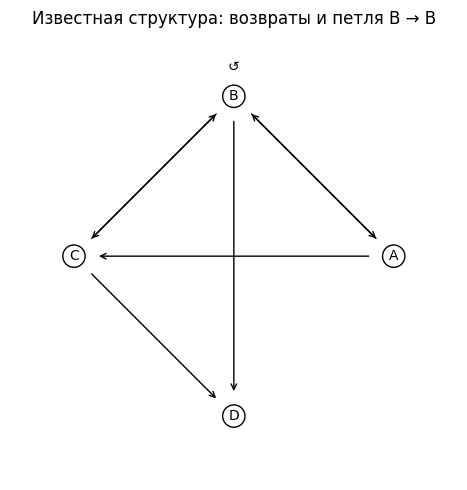

In [2]:
START, TERMINAL = "A", "D"
ORIGIN = pd.Timestamp("2025-01-01", tz="UTC")
DAY = pd.Timedelta(days=1)
TRUE_RATES = {("A", "B"): .35, ("A", "C"): .15,
              ("B", "A"): .06, ("B", "B"): .04,
              ("B", "C"): .20, ("B", "D"): .12,
              ("C", "B"): .10, ("C", "D"): .25}
network = Network.from_edges(list(TRUE_RATES), starts=[START], terminals=[TERMINAL])
truth = ProcessModel(network, ExponentialTransitionModel(rates=TRUE_RATES))
true_parameters = truth.edges_table().rename(columns={"rate": "true_rate",
                                                        "p": "true_winner_p",
                                                        "mean_days": "true_min_mean_days"})
true_parameters["true_clock_mean_days"] = 1 / true_parameters.true_rate
display(true_parameters.drop(columns=["n_completed", "n_visits"]))
fig, ax = plt.subplots(figsize=(7, 5))
network.plot(ax=ax)
ax.set_title("Известная структура: возвраты и петля B → B")
fig.tight_layout()

## 2. Полные траектории → независимое прекращение наблюдения

Сначала `Simulator` генерирует полные траектории до D (технический предел 500 дней).
Затем каждому объекту независимо назначаем exponential dropout со средним 12 дней
и административный конец через 20 дней. Наблюдение кончается при первом из терминала,
dropout и административного конца. События **и замеры** после этого момента исключаются;
конец и причина сохраняются в `observation`. Время истинного терминала храним отдельно
только для проверки синтетики и не передаём обучению.

In [3]:
def make_sample(n, seed, prefix, loss_mean=12., admin_days=20.):
    initial = [dict(case_id=f"{prefix}-{i:05d}", state=START, t=ORIGIN,
                    X={"marker": float(i % 3)}) for i in range(n)]
    full = Simulator(truth, seed=seed).run(ObjectStream(initial), horizon=500)
    assert full.observation.event.eq(1).all(), "Увеличьте технический горизонт генерации"
    terminal = full.observation.set_index("case_id").end
    rng = np.random.default_rng(seed + 100_000)
    dropout = pd.Series(ORIGIN + pd.to_timedelta(rng.exponential(loss_mean, n), unit="D"),
                        index=terminal.index)
    admin = ORIGIN + admin_days * DAY
    end = pd.concat([terminal, dropout, pd.Series(admin, index=terminal.index)], axis=1).min(axis=1)
    event = terminal.le(end)
    reason = np.where(event, "", np.where(dropout.le(admin), "dropout", "study_end"))
    observation = pd.DataFrame(dict(case_id=end.index, end=end.array,
                                    event=event.astype(int).to_numpy(), reason=reason))
    events = full.events.loc[full.events.timestamp.le(full.events.case_id.map(end))].copy()
    measurements = full.measurements.loc[
        full.measurements.timestamp.le(full.measurements.case_id.map(end))].copy()
    observed = EventLog(events, full.cases.copy(), measurements, end, observation)
    reference = pd.DataFrame({"true_terminal": terminal, "observation_end": end})
    assert observed.events.timestamp.le(observed.events.case_id.map(end)).all()
    assert observed.measurements.timestamp.le(observed.measurements.case_id.map(end)).all()
    return observed.prepare(dict(starts=[START], terminals=[TERMINAL], min_duration=1e-9)), reference

train, train_truth = make_sample(1200, 2026, "train")
test, test_truth = make_sample(400, 7, "test")
assert set(train.cases.index).isdisjoint(test.cases.index)
iv = train.intervals()
print("Train/test объектов:", len(train.cases), len(test.cases))
display(train.observation.groupby(["event", "reason"]).size().rename("cases"))
display(censoring_summary(iv))
display(iv.head())

Train/test объектов: 1200 400


event  reason   
0      dropout      501
       study_end     14
1                   685
Name: cases, dtype: int64

,src,n_visits,n_completed,p_completed,q_censored,n_dropout,q_dropout,n_study_end,q_study_end
0,A,1338,1164,0.8700,0.1300,173,0.1293,1,0.0007
1,B,1082,877,0.8105,0.1895,195,0.1802,10,0.0092
2,C,761,625,0.8213,0.1787,133,0.1748,3,0.0039


,case_id,src,dst,duration,observed,reason,enter
0,train-00000,A,B,0.4054,True,,2025-01-01 00:00:00+00:00
1,train-00000,B,A,0.0311,True,,2025-01-01 09:43:48.738869242+00:00
2,train-00000,A,B,0.4022,True,,2025-01-01 10:28:37.904257372+00:00
3,train-00000,B,C,1.1682,True,,2025-01-01 20:07:50.254315243+00:00
4,train-00000,C,D,1.3256,True,,2025-01-03 00:09:58.814772869+00:00


## 3. Обучение и восстановление интенсивностей

Для исходного состояния s каждый интервал даёт экспозицию **всем** исходящим часам:
`rate(s,d) = число выходов s→d / суммарное время в s`, включая цензурированные ожидания.
Логарифм вклада завершённого интервала: `log(rate(s,d)) − sum(rate(s,*)) × t`;
цензурированного: `−sum(rate(s,*)) × t`.

Сравниваем censor-aware оценку с `use_censoring=False`, которая выбрасывает последние
цензурированные интервалы. Это наивный ориентир. Ошибку считаем по всем заданным рёбрам,
включая редкие рёбра с нулём событий. Истинные средние часов равны `1/rate`,
вероятность победы `rate/sum(rate)`, а среднее минимума `1/sum(rate)`.

In [4]:
aware = ProcessModel(network).fit(train)
naive = ProcessModel(network).fit(train, use_censoring=False)
models = {"censor_aware": aware, "naive_completed_only": naive}
recovery = true_parameters[["src", "dst", "true_rate", "true_winner_p", "true_min_mean_days"]].copy()
for name, model in models.items():
    estimate = model.edges_table()[["src", "dst", "n_completed", "rate"]]
    estimate = estimate.rename(columns={"rate": name, "n_completed": f"{name}_events"})
    recovery = recovery.merge(estimate, on=["src", "dst"], how="left", validate="one_to_one")
    recovery[f"{name}_relative_error"] = recovery[name] / recovery.true_rate - 1

display(recovery)
display(pd.DataFrame([dict(model=name,
    mean_absolute_rate_error=np.mean([abs(model.transitions.rates[e] - r) for e, r in TRUE_RATES.items()]),
    zero_rate_edges=sum(model.transitions.rates[e] == 0 for e in TRUE_RATES))
    for name, model in models.items()]))
# Независимая проверка формулы MLE по экспозиции.
for (src, dst), rate in aware.transitions.rates.items():
    group = iv.loc[iv.src == src]
    expected = (group.observed & group.dst.eq(dst)).sum() / group.duration.sum()
    assert np.isclose(rate, expected)

,src,dst,true_rate,true_winner_p,true_min_mean_days,censor_aware_events,censor_aware,censor_aware_relative_error,naive_completed_only_events,naive_completed_only,naive_completed_only_relative_error
0,A,B,0.35,0.7000,2.0000,822,0.3446,-0.0153,822,0.3917,0.1191
1,A,C,0.15,0.3000,2.0000,342,0.1434,-0.0440,342,0.1630,0.0865
2,B,A,0.06,0.1429,2.3810,138,0.0634,0.0563,138,0.0792,0.3194
3,B,B,0.04,0.0952,2.3810,80,0.0367,-0.0815,80,0.0459,0.1473
4,B,C,0.20,0.4762,2.3810,419,0.1924,-0.0379,419,0.2404,0.2018
5,B,D,0.12,0.2857,2.3810,240,0.1102,-0.0815,240,0.1377,0.1473
6,C,B,0.10,0.2857,2.8571,180,0.1001,0.0006,180,0.1191,0.1911
7,C,D,0.25,0.7143,2.8571,445,0.2474,-0.0105,445,0.2945,0.1778


,model,mean_absolute_rate_error,zero_rate_edges
0,censor_aware,0.0048,0
1,naive_completed_only,0.0252,0


## 4. Отдельно структура, часы и наблюдаемое ожидание

DFG обнаруживаем только на train, затем сравниваем с известной структурой. На левом рисунке
плотность **минимума** из A сопоставлена с полными синтетическими ожиданиями, без отбора
dropout. Пунктир показывает истинную плотность отдельного часа A→B и не трактуется как
плотность наблюдаемого ожидания выбранного ребра. На правом рисунке — совместная CDF
`P(следующий выход B, ожидание ≤ t)`, стремящаяся к вероятности победы, а не к единице.

precision
recall
f1
missing
extra
Диагностика обнаруженной сети:


1.0

1.0

1.0

,src,dst


,src,dst


,state,issue


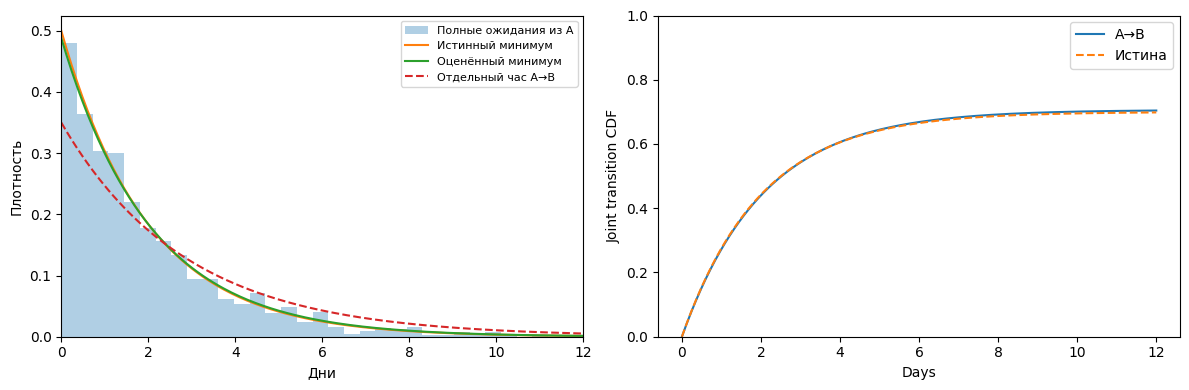

In [5]:
found = discover(train, DirectlyFollowsBackend(starts=[START], terminals=[TERMINAL]))
topology = compare_networks(network, found)
for name, table in topology.items():
    print(name)
    display(table)
print("Диагностика обнаруженной сети:")
display(found.validate())

# Дополнительная независимая нецензурированная выборка — только для рисунка.
complete = Simulator(truth, seed=33).run(ObjectStream([
    dict(case_id=f"curve-{i}", state=START, t=ORIGIN, X={}) for i in range(1200)]), horizon=500)
complete_iv = complete.prepare(dict(starts=[START], terminals=[TERMINAL], min_duration=1e-9)).intervals()
assert complete.observation.event.eq(1).all()
times = np.linspace(0, 12, 200)
true_total = sum(r for (src, dst), r in TRUE_RATES.items() if src == START)
fit_total = sum(aware.transition_parameters(START).values())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(complete_iv.loc[complete_iv.src.eq(START), "duration"], bins=45,
             density=True, alpha=.35, label="Полные ожидания из A")
axes[0].plot(times, true_total*np.exp(-true_total*times), label="Истинный минимум")
axes[0].plot(times, fit_total*np.exp(-fit_total*times), label="Оценённый минимум")
clock = TRUE_RATES[START, "B"]
axes[0].plot(times, clock*np.exp(-clock*times), "--", label="Отдельный час A→B")
axes[0].set(xlabel="Дни", ylabel="Плотность", xlim=(0, 12))
axes[0].legend(fontsize=8)
viz = MatplotlibVisualizer()
viz.plot_edge_curves(aware, (START, "B"), times, ax=axes[1])
axes[1].plot(times, clock/true_total*(1-np.exp(-true_total*times)), "--", label="Истина")
axes[1].legend()
fig.tight_layout()

## 5. Holdout и размер обучающей выборки

NLL вычисляется на всех интервалах отдельных test-объектов, с их цензурой. Меньше — лучше;
NLL плотности может быть отрицательным. Нулевой rate наблюдаемого test-перехода даёт `inf`.
Ничего не сглаживаем и не исключаем. Повторы ниже — небольшой численный опыт,
не доверительный интервал и не гарантия монотонного улучшения каждого запуска.

,model,metric,value
0,censor_aware,nll_per_interval,2.1593
1,censor_aware,nll_per_trace,5.5603
2,naive_completed_only,nll_per_interval,2.1625
3,naive_completed_only,nll_per_trace,5.5686


,n_train,repeat,model,rate_mae,zero_rate_edges,test_nll
0,100,0,censor_aware,0.0305,0,2.1955
1,100,0,naive_completed_only,0.0474,0,2.1982
2,100,1,censor_aware,0.0235,0,2.1724
3,100,1,naive_completed_only,0.0217,0,2.1672
4,100,2,censor_aware,0.0249,0,2.1645
5,100,2,naive_completed_only,0.0522,0,2.1861
6,300,0,censor_aware,0.0112,0,2.1642
7,300,0,naive_completed_only,0.0366,0,2.1723
8,300,1,censor_aware,0.0174,0,2.1774
9,300,1,naive_completed_only,0.0256,0,2.1755


rate_mae_mean  rate_mae_std  zero_edges_total  \
n_train model                                                                 
100     censor_aware                 0.0263        0.0037                 0   
        naive_completed_only         0.0404        0.0164                 0   
300     censor_aware                 0.0128        0.0040                 0   
        naive_completed_only         0.0302        0.0057                 0   
1000    censor_aware                 0.0066        0.0024                 0   
        naive_completed_only         0.0352        0.0044                 0   

                              infinite_test_runs  
n_train model                                     
100     censor_aware                           0  
        naive_completed_only                   0  
300     censor_aware                           0  
        naive_completed_only                   0  
1000    censor_aware                           0  
        naive_completed_only                   0

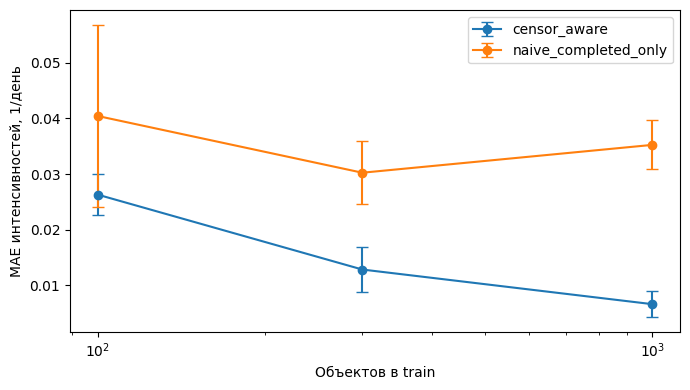

In [6]:
holdout = compare(models, test, metrics=["nll"])
display(holdout)
rows = []
for n in [100, 300, 1000]:
    for repeat in range(3):
        sample, _ = make_sample(n, 4100 + repeat + n, f"n{n}-r{repeat}")
        for name, censoring in [("censor_aware", True), ("naive_completed_only", False)]:
            model = ProcessModel(network).fit(sample, use_censoring=censoring)
            result = evaluate(model, test, metrics=["nll"])["nll"].set_index("metric").value
            errors = [abs(model.transitions.rates[e] - r) for e, r in TRUE_RATES.items()]
            rows.append(dict(n_train=n, repeat=repeat, model=name,
                             rate_mae=np.mean(errors),
                             zero_rate_edges=sum(model.transitions.rates[e] == 0 for e in TRUE_RATES),
                             test_nll=result["nll_per_interval"]))
size_results = pd.DataFrame(rows)
display(size_results)
# Бесконечные NLL явно считаются; среднее NLL не выводим через groupby, скрывающий inf.
size_summary = size_results.groupby(["n_train", "model"]).agg(
    rate_mae_mean=("rate_mae", "mean"), rate_mae_std=("rate_mae", "std"),
    zero_edges_total=("zero_rate_edges", "sum"),
    infinite_test_runs=("test_nll", lambda x: int(np.isinf(x).sum())))
display(size_summary)
fig, ax = plt.subplots(figsize=(7, 4))
for name, group in size_results.groupby("model"):
    summary = group.groupby("n_train").rate_mae.agg(["mean", "std"])
    ax.errorbar(summary.index, summary["mean"], yerr=summary["std"], marker="o", capsize=4, label=name)
ax.set(xlabel="Объектов в train", ylabel="MAE интенсивностей, 1/день", xscale="log")
ax.legend()
fig.tight_layout()

## 6. Весь путь до D

Прогноз включает петли, возвраты и все промежуточные состояния. Начинаем с A в момент входа;
не передаём истинное будущее test-объекта. Сравниваем Monte Carlo survival для истины
и двух оценок, по 300 путей на модель. Это оценка с шумом симуляции.

,horizon,survival,cdf,model
0,0.0,1.0000,0.0000,truth
7,7.0,0.4333,0.5667,truth
14,14.0,0.1233,0.8767,truth
30,30.0,0.0033,0.9967,truth
0,0.0,1.0000,0.0000,censor_aware
7,7.0,0.4633,0.5367,censor_aware
14,14.0,0.1367,0.8633,censor_aware
30,30.0,0.0033,0.9967,censor_aware
0,0.0,1.0000,0.0000,naive_completed_only
7,7.0,0.3567,0.6433,naive_completed_only


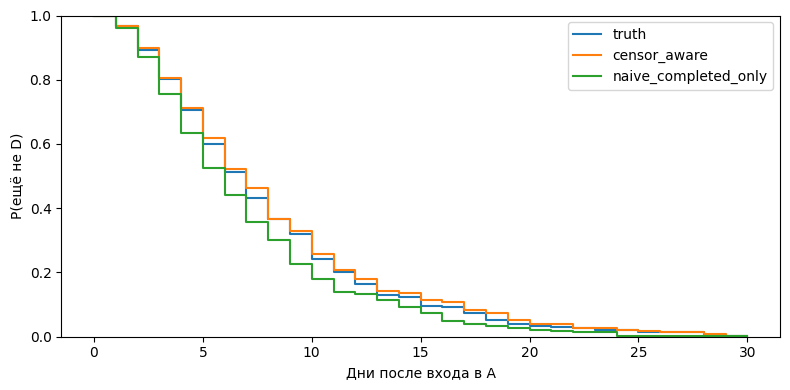

In [7]:
case_id = test.events.case_id.iloc[0]
times = np.linspace(0, 30, 31)
forecast_tables = []
fig, ax = plt.subplots(figsize=(8, 4))
for name, model in {"truth": truth, **models}.items():
    forecast = Forecaster(model, n_paths=300, seed=55).survival(
        test, ORIGIN, times, case_id=case_id)
    forecast_tables.append(forecast.assign(model=name))
    ax.step(forecast.horizon, forecast.survival, where="post", label=name)
ax.set(xlabel="Дни после входа в A", ylabel="P(ещё не D)", ylim=(0, 1))
ax.legend()
fig.tight_layout()
display(pd.concat(forecast_tables).query("horizon in [0, 7, 14, 30]"))

## Ограничения интерпретации

Результаты таблиц и рисунков получены текущим запуском. Интенсивности сравнимы с истиной
потому, что генератор и оценка используют один exponential min-time закон и независимую
цензуру. Это не доказывает пригодность такого закона для Sepsis. Редкое ребро может
не встретиться, его MLE будет нулевой; увеличение выборки не гарантирует улучшение
в каждом конкретном повторе. DFG не восстанавливает параллелизм общей сети Петри.
V2 здесь проверяет NLL и топологию; AIC между семействами и старый набор allmetrics
к этому опыту не применяются. Файлы результатов автоматически не создаются.